# Чекпоинт 2. Разведочный анализ данных (EDA)

**Задача проекта:** прогноз цены карбамида на 1 и 3 месяца. Цена = газовая составляющая (k × цена газа TTF) + надбавка; модель прогнозирует надбавку.

**Данные этого ноутбука:** World Bank Pink Sheet — 20 месячных рядов цен: энергоносители, удобрения, сельхозкультуры, металлы. Данные PortWatch, GSCPI, Comtrade и ставки разбираются в отдельных ноутбуках команды.

**Периоды:** рабочий — апрель 2015 – сентябрь 2026 (с апреля 2015 газ Европы = TTF). Трейн — апрель 2015 – сентябрь 2023, тест — октябрь 2023 – сентябрь 2026. Все выводы о связях делаем **только на трейне**.

**Две целевые переменные для анализа:**
- target_markup — надбавка через месяц: urea_price(t+1) − k · gas_europe(t), k = 12 (наклон цены по газу на трейне, см. 01_eda_prices.ipynb, разделы 10–11);
- target_change — изменение цены карбамида за следующий месяц, лог-доходность ln(urea(t+1) / urea(t)).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.read_excel("../data/raw/CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices", header=None)

header_row = raw.index[raw.astype(str).apply(lambda r: r.str.strip().str.startswith("Urea").any(), axis=1)][0]
columns = raw.iloc[header_row].fillna("").astype(str).str.strip().str.replace(r"\s*\*+$", "", regex=True)
body = raw.iloc[header_row + 2:].copy()
body.columns = columns
body = body[body.iloc[:, 0].astype(str).str.match(r"^\d{4}M\d{2}$")]
body.index = pd.to_datetime(body.iloc[:, 0].str.replace("M", "-") + "-01")

names = {
    "Crude oil, Brent": "brent", "Coal, Australian": "coal_aus", "Coal, South African": "coal_safr",
    "Natural gas, US": "gas_us", "Natural gas, Europe": "gas_europe", "Liquefied natural gas, Japan": "lng_japan",
    "Urea": "urea_price", "DAP": "dap", "TSP": "tsp", "Phosphate rock": "phosphate_rock", "Potassium chloride": "potash",
    "Maize": "maize", "Wheat, US HRW": "wheat", "Soybeans": "soybeans", "Rice, Thai 5%": "rice",
    "Sugar, world": "sugar", "Palm oil": "palm_oil", "Copper": "copper", "Iron ore, cfr spot": "iron_ore", "Aluminum": "aluminum",
}
full = pd.DataFrame({new: pd.to_numeric(body[old].replace("…", np.nan), errors="coerce") for old, new in names.items()})

df = full.loc["2015-04":].copy()
K = 12
df["markup"] = df["urea_price"] - K * df["gas_europe"]
df["target_markup"] = df["urea_price"].shift(-1) - K * df["gas_europe"]
df["target_change"] = np.log(df["urea_price"].shift(-1) / df["urea_price"])
df["regime"] = "спокойно"
df.loc["2021-07":"2022-12", "regime"] = "кризис"
df.loc["2023-01":, "regime"] = "после кризиса"
df["regime"] = df["regime"].astype("category")

train = df.loc[:"2023-09"]
prices = list(names.values())
print("Вся история:", full.index.min().date(), "–", full.index.max().date(), len(full), "мес.")
print("Рабочий период:", df.index.min().date(), "–", df.index.max().date(), len(df), "мес.; трейн:", len(train))

Вся история: 1960-01-01 – 2026-09-01 801 мес.
Рабочий период: 2015-04-01 – 2026-09-01 138 мес.; трейн: 102


## 1. Особенности данных

### 1.1. Основные статистики
Все признаки — цены (вещественные), плюс одна категориальная колонка regime (режим рынка). describe(include='all') показывает для чисел среднее, разброс и квантили, для категории — число уникальных значений и самое частое.

In [2]:
pd.set_option("display.max_columns", 30)
df.describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brent,138.0,NaN,NaN,NaN,68.515942,19.527847,23.3,54.925,67.85,80.725,120.4
coal_aus,138.0,NaN,NaN,NaN,125.413043,81.774331,49.0,72.55,105.65,139.05,430.8
coal_safr,138.0,NaN,NaN,NaN,102.35942,51.193427,48.8,73.8,92.5,105.3,302.0
gas_us,138.0,NaN,NaN,NaN,3.148188,1.355251,1.5,2.365,2.825,3.2225,8.79
gas_europe,138.0,NaN,NaN,NaN,11.813986,11.129531,1.58,5.1575,8.03,13.16,70.04
lng_japan,138.0,NaN,NaN,NaN,11.402246,3.33991,5.88,9.085,10.91,12.71,23.73
urea_price,138.0,NaN,NaN,NaN,351.663768,174.009508,142.6,233.825,286.15,394.475,925.0
dap,138.0,NaN,NaN,NaN,493.64058,175.894212,238.2,326.275,433.05,623.55,954.0
tsp,138.0,NaN,NaN,NaN,437.877536,157.390571,239.0,291.6,382.5,546.0,856.0
phosphate_rock,138.0,NaN,NaN,NaN,146.033333,78.658343,70.8,91.6,121.8,152.5,347.5


**Что видно:** у всех цен большой разброс (у газа Европы min 1,6 и max 70 \$/млн БТЕ — в 44 раза), средние сильно больше медиан — распределения скошены вправо из-за кризиса 2021–2022. Сахар в \$/кг, остальное в \$/т или \$/баррель — масштабы разные, поэтому связи смотрим через корреляции и проценты, а не через уровни.

### 1.2. Пропуски
**Гипотеза:** пропуски в Pink Sheet — это не потерянные данные, а месяцы, **когда ряд ещё не публиковался** (знак «…» в файле). Если гипотеза верна, пропуски стоят только в начале ряда и ни одного «дырявого» месяца внутри нет.

In [3]:
missing = pd.DataFrame({
    "пропусков, вся история": full.isna().sum(),
    "доля, %": (full.isna().mean() * 100).round(1),
    "первое значение": full.apply(lambda s: s.first_valid_index().date()),
    "пропусков внутри ряда": full.apply(lambda s: s.loc[s.first_valid_index():].isna().sum()),
    "пропусков с апреля 2015": full.loc["2015-04":].isna().sum(),
})
print("Доля пропусков во всей таблице 1960–2026:", round(full.isna().mean().mean() * 100, 1), "%")
missing.sort_values("доля, %", ascending=False)

Доля пропусков во всей таблице 1960–2026: 4.3 %


,"пропусков, вся история","доля, %",первое значение,пропусков внутри ряда,пропусков с апреля 2015
coal_safr,288,36.0,1984-01-01,0,0
lng_japan,204,25.5,1977-01-01,0,0
coal_aus,120,15.0,1970-01-01,0,0
dap,84,10.5,1967-01-01,0,0
gas_us,0,0.0,1960-01-01,0,0
brent,0,0.0,1960-01-01,0,0
gas_europe,0,0.0,1960-01-01,0,0
urea_price,0,0.0,1960-01-01,0,0
tsp,0,0.0,1960-01-01,0,0
phosphate_rock,0,0.0,1960-01-01,0,0


**Вывод:** гипотеза подтверждается — пропуски есть только у рядов, которые начинаются позже 1960 года (уголь ЮАР с 1984, СПГ Японии с 1977, уголь Австралии с 1970, DAP с 1967), **внутри рядов пропусков нет**, а в рабочем периоде с апреля 2015 их ноль. Датасет не разрежен.

**Обработка:** работаем с апреля 2015 — пропуски не нужно заполнять. Для будущих источников (PortWatch, GSCPI) правило: заполняем только прошлым значением (ffill) не дольше 2 месяцев с флагом «был пропуск»; заполнять будущим (bfill) нельзя — это утечка.

### 1.3. Ошибочные значения
Проверяем: отрицательные и нулевые цены, дубли месяцев, пропущенные месяцы в календаре. Отдельно — смены методики, которые не видны как «ошибка», но ломают сопоставимость ряда.

In [4]:
checks = pd.DataFrame({
    "цена ≤ 0": (df[prices] <= 0).sum(),
    "min": df[prices].min(),
    "max": df[prices].max(),
})
print("Дубли месяцев:", df.index.duplicated().sum())
expected = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Пропущенных месяцев в календаре:", len(expected.difference(df.index)))
print("Отрицательная надбавка (не ошибка, а кризисный режим), месяцев:", (df["markup"] < 0).sum())
checks.round(1)

Дубли месяцев: 0
Пропущенных месяцев в календаре: 0
Отрицательная надбавка (не ошибка, а кризисный режим), месяцев: 3


,цена ≤ 0,min,max
brent,0,23.3,120.4
coal_aus,0,49.0,430.8
coal_safr,0,48.8,302.0
gas_us,0,1.5,8.8
gas_europe,0,1.6,70.0
lng_japan,0,5.9,23.7
urea_price,0,142.6,925.0
dap,0,238.2,954.0
tsp,0,239.0,856.0
phosphate_rock,0,70.8,347.5


**Вывод:** отрицательных и нулевых цен, дублей и пропущенных месяцев нет. Отрицательная надбавка — **не ошибка**: так бывает, когда газ в Европе настолько дорог, что цену задают производители с дешёвым газом.

**Смены методики (лист Description файла World Bank)** — главные «ошибки» сопоставимости:

| Ряд | Что изменилось | Как учитываем |
|---|---|---|
| Газ Европы | с апреля 2015 — TTF, раньше цена импорта на границе | берём период с апреля 2015 |
| Карбамид | с марта 2022 — FOB Ближний Восток, раньше FOB Чёрное море | флаг fob_me с марта 2022 |
| Калий (potash) | с января 2020 — CFR Бразилия, раньше FOB Ванкувер | учитываем при интерпретации калия |
| СПГ Японии | последние 2 месяца — оценка, потом пересматривается | не используем последние 2 месяца |
| Пальмовое масло | несколько смен площадки в 2020–2026 | в модель не берём |

### 1.4. Выбросы
Цены — блуждающие ряды, поэтому выбросы ищем не в уровнях, а в **месячных изменениях** (лог-доходность). Выброс — изменение дальше 3 стандартных отклонений от среднего по трейну.

Число выбросов по рядам:
gas_us            6
potash            4
phosphate_rock    4
brent             3
coal_aus          3
dap               3
urea_price        3
tsp               2
coal_safr         2
soybeans          2
gas_europe        1
lng_japan         1
wheat             1
sugar             1
palm_oil          1
copper            1
aluminum          1
urea_price : 2021-10 (+51%), 2026-03 (+43%), 2026-06 (-53%)
gas_europe : 2023-01 (-58%)
brent : 2020-03 (-51%), 2020-04 (-35%), 2026-03 (+38%)
dap : 2021-02 (+23%), 2022-03 (+23%), 2023-05 (-22%)


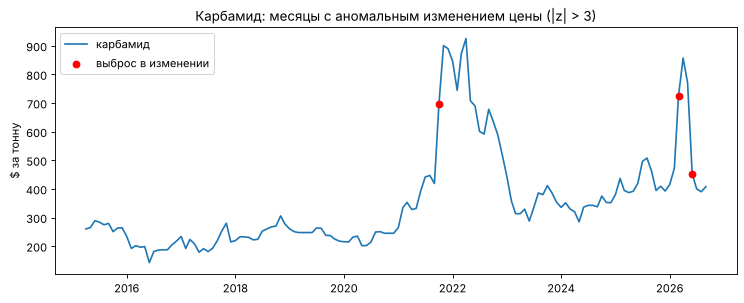

In [5]:
changes = np.log(df[prices]).diff()
z = (changes - changes.loc[:"2023-09"].mean()) / changes.loc[:"2023-09"].std()
outliers = z.abs() > 3
print("Число выбросов по рядам:")
print(outliers.sum()[outliers.sum() > 0].sort_values(ascending=False).to_string())
for col in ["urea_price", "gas_europe", "brent", "dap"]:
    months = [f"{d:%Y-%m} ({changes.loc[d, col] * 100:+.0f}%)" for d in df.index[outliers[col]]]
    print(col, ":", ", ".join(months))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df["urea_price"], label="карбамид")
ax.scatter(df.index[outliers["urea_price"]], df.loc[outliers["urea_price"], "urea_price"], color="red", zorder=3, label="выброс в изменении")
ax.set_ylabel("$ за тонну")
ax.set_title("Карбамид: месяцы с аномальным изменением цены (|z| > 3)")
ax.legend()
plt.show()

**Вывод:** у карбамида три выброса — октябрь 2021 (+51%: газовый кризис и ограничения экспорта Китая), март 2026 (+43%: сбой судоходства в районе Ормуза) и июнь 2026 (−53%: обратное движение). Нефть — март–апрель 2020 (пандемия) и март 2026. Газ Европы — январь 2023 (−58%: обвал после пика 2022).

Все выбросы — **реальные рыночные события**, а не ошибки ввода. **Не удаляем:** именно шоки модель и должна научиться предсказывать, а наивный прогноз проигрывает как раз на них. **Обработка:** флаги режимов (regime), отдельная оценка качества по спокойным и кризисным месяцам; для линейных моделей — устойчивые к выбросам функции потерь (Huber) как вариант.

## 2. Признаки и их связь с целевой переменной

### 2.1. Распределения: уровни и изменения

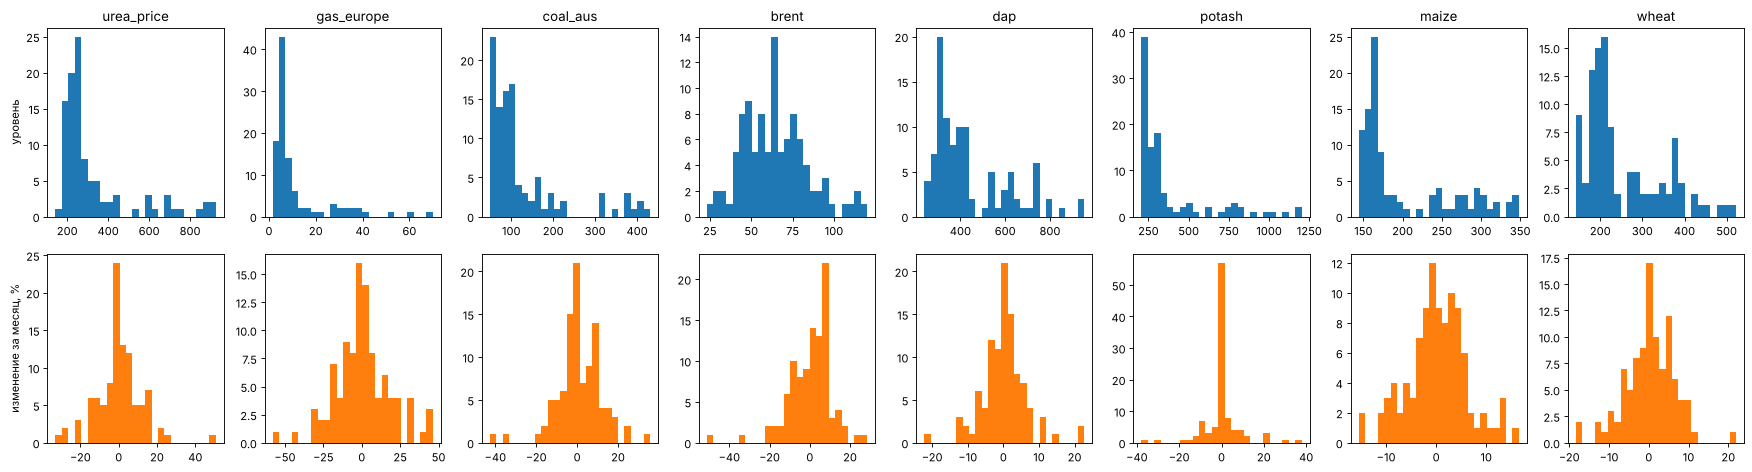

In [6]:
key = ["urea_price", "gas_europe", "coal_aus", "brent", "dap", "potash", "maize", "wheat"]
fig, axes = plt.subplots(2, len(key), figsize=(22, 6))
for i, col in enumerate(key):
    axes[0, i].hist(train[col], bins=25)
    axes[0, i].set_title(col)
    axes[1, i].hist(np.log(train[col]).diff().dropna() * 100, bins=25, color="tab:orange")
axes[0, 0].set_ylabel("уровень")
axes[1, 0].set_ylabel("изменение за месяц, %")
plt.tight_layout()
plt.show()

**Вывод:** уровни распределены с длинным хвостом вправо и часто двугорбо (спокойные годы и кризис — разные «горки»), поэтому уровни плохо подходят как признаки напрямую. Месячные изменения — симметричные, около нуля, с тяжёлыми хвостами (шоки). Для модели берём **изменения и разницы**, а не уровни.

### 2.2. Сводные таблицы

In [7]:
key_with_markup = key + ["markup"]
print("Медиана по режимам рынка:")
display(df.pivot_table(index="regime", values=key_with_markup, aggfunc="median", observed=True).T.round(1))
print("Среднее по годам:")
display(df[key_with_markup].groupby(df.index.year).mean().round(0))

Медиана по режимам рынка:
Среднее по годам:


regime,кризис,после кризиса,спокойно
brent,90.6,80.1,55.5
coal_aus,312.4,135.1,80.0
dap,735.8,612.5,335.0
gas_europe,32.9,11.8,5.4
maize,297.4,206.5,163.6
markup,289.3,220.7,177.8
potash,788.8,352.0,245.5
urea_price,684.0,385.6,237.0
wheat,384.6,274.8,199.5


,urea_price,gas_europe,coal_aus,brent,dap,potash,maize,wheat,markup
,,,,,,,,,
2015,270.0,6.0,57.0,52.0,410.0,301.0,168.0,193.0,195.0
2016,194.0,5.0,66.0,44.0,316.0,260.0,159.0,167.0,139.0
2017,214.0,6.0,89.0,54.0,323.0,218.0,155.0,174.0,145.0
2018,249.0,8.0,107.0,71.0,393.0,216.0,164.0,210.0,157.0
2019,245.0,5.0,78.0,64.0,306.0,256.0,170.0,202.0,188.0
2020,229.0,3.0,61.0,42.0,312.0,241.0,165.0,232.0,190.0
2021,483.0,16.0,138.0,70.0,601.0,543.0,260.0,315.0,290.0
2022,700.0,40.0,345.0,100.0,772.0,863.0,319.0,430.0,216.0
2023,358.0,13.0,173.0,83.0,550.0,383.0,253.0,340.0,201.0


**Вывод:** в кризис 2021–2022 подорожало всё: газ Европы в 6 раз (медиана 5,4 → 32,9), уголь в 4 раза, карбамид почти в 3 раза, DAP и калий — в 2–3 раза. После кризиса цены не вернулись к уровню 2015–2020: карбамид около \$390 против \$240, газ около 12 против 5. Надбавка при k = 12 (медиана) в спокойные годы около \$180, после кризиса около \$220 — норма сдвинулась вверх (возможна связь со сменой котировки карбамида в 2022).

### 2.3. Матрица корреляций: уровни против изменений
Главная ловушка временных рядов: **уровни** всех цен растут и падают вместе (общий тренд, инфляция, кризис), поэтому корреляции уровней высокие и почти ничего не говорят о причинах. Честную картину дают корреляции **месячных изменений**.

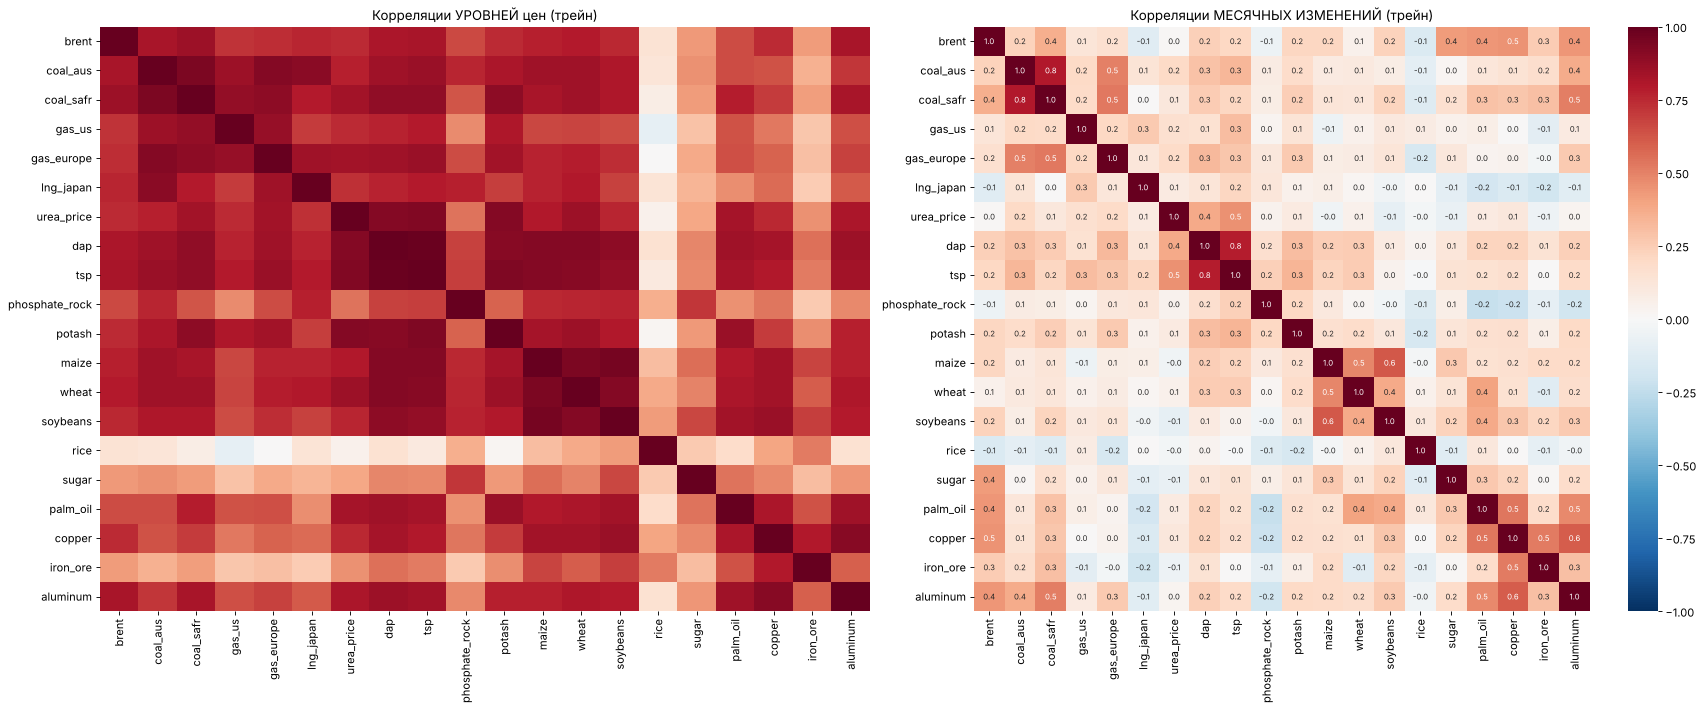

In [8]:
corr_levels = train[prices].corr()
corr_changes = np.log(train[prices]).diff().corr()

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(corr_levels, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Корреляции УРОВНЕЙ цен (трейн)")
sns.heatmap(corr_changes, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], annot=True, fmt=".1f", annot_kws={"size": 7})
axes[1].set_title("Корреляции МЕСЯЧНЫХ ИЗМЕНЕНИЙ (трейн)")
plt.tight_layout()
plt.show()

**Вывод:** в уровнях почти всё связано со всем (0,7–0,9) — это общий тренд, а не связь. В изменениях картина чище и осмысленнее: видны **кластеры** — уголь Австралии и ЮАР (0,8), газ Европы с углём (0,5), фосфорные удобрения DAP и TSP (0,8), зерновые: кукуруза, соя, пшеница (0,4–0,6), металлы (0,5–0,6). Карбамид в тот же месяц сильнее всего связан с другими удобрениями (DAP 0,4, TSP 0,5), а с газом и углём — слабо (0,1–0,2): газ действует с запаздыванием, это видно в 2.4.

### 2.4. Связь с целевой переменной
Признак на месяц t против цели на месяц t+1 — только так признак можно использовать для прогноза. Порог случайности для корреляции на трейне ≈ ±0,2.

In [9]:
changes_train = np.log(train[prices]).diff()
target_links = pd.DataFrame({
    "изменение сейчас → изменение цены в след. месяце": changes_train.corrwith(train["target_change"]),
    "изменение сейчас → надбавка в след. месяце": changes_train.corrwith(train["target_markup"]),
    "уровень сейчас → надбавка в след. месяце": train[prices].corrwith(train["target_markup"]),
}).round(2)
print("Порог случайности:", round(1.96 / np.sqrt(len(train) - 2), 2))
target_links.sort_values("изменение сейчас → изменение цены в след. месяце", ascending=False)

Порог случайности: 0.2


,изменение сейчас → изменение цены в след. месяце,изменение сейчас → надбавка в след. месяце,уровень сейчас → надбавка в след. месяце
gas_europe,0.38,0.11,-0.02
dap,0.31,0.32,0.33
coal_aus,0.28,0.17,-0.06
aluminum,0.28,0.14,0.48
brent,0.26,0.23,0.20
coal_safr,0.25,0.19,0.10
gas_us,0.25,0.15,0.02
copper,0.22,0.06,0.50
tsp,0.21,0.34,0.31
lng_japan,0.19,0.08,-0.06


**Вывод:** изменение цены карбамида в следующем месяце сильнее всего связано с тем, как **в этом месяце** изменились газ Европы (0,38), DAP (0,31), уголь (0,28) и нефть (0,26). Само прошлое изменение карбамида почти ничего не говорит о следующем (0,08). Для надбавки следующего месяца важнее изменения других удобрений: калий (0,41), TSP (0,34), DAP (0,32). Зерновые связаны слабо. Корреляции **уровней** с надбавкой (медь 0,50, пальмовое масло 0,53) — эффект общего тренда, в признаки их не берём. Кандидаты в признаки: изменения газа, угля, нефти и других удобрений за последний месяц.

### 2.5. Попарные распределения (pairplot)
Месячные изменения ключевых рядов и цель. Цвет — режим рынка.

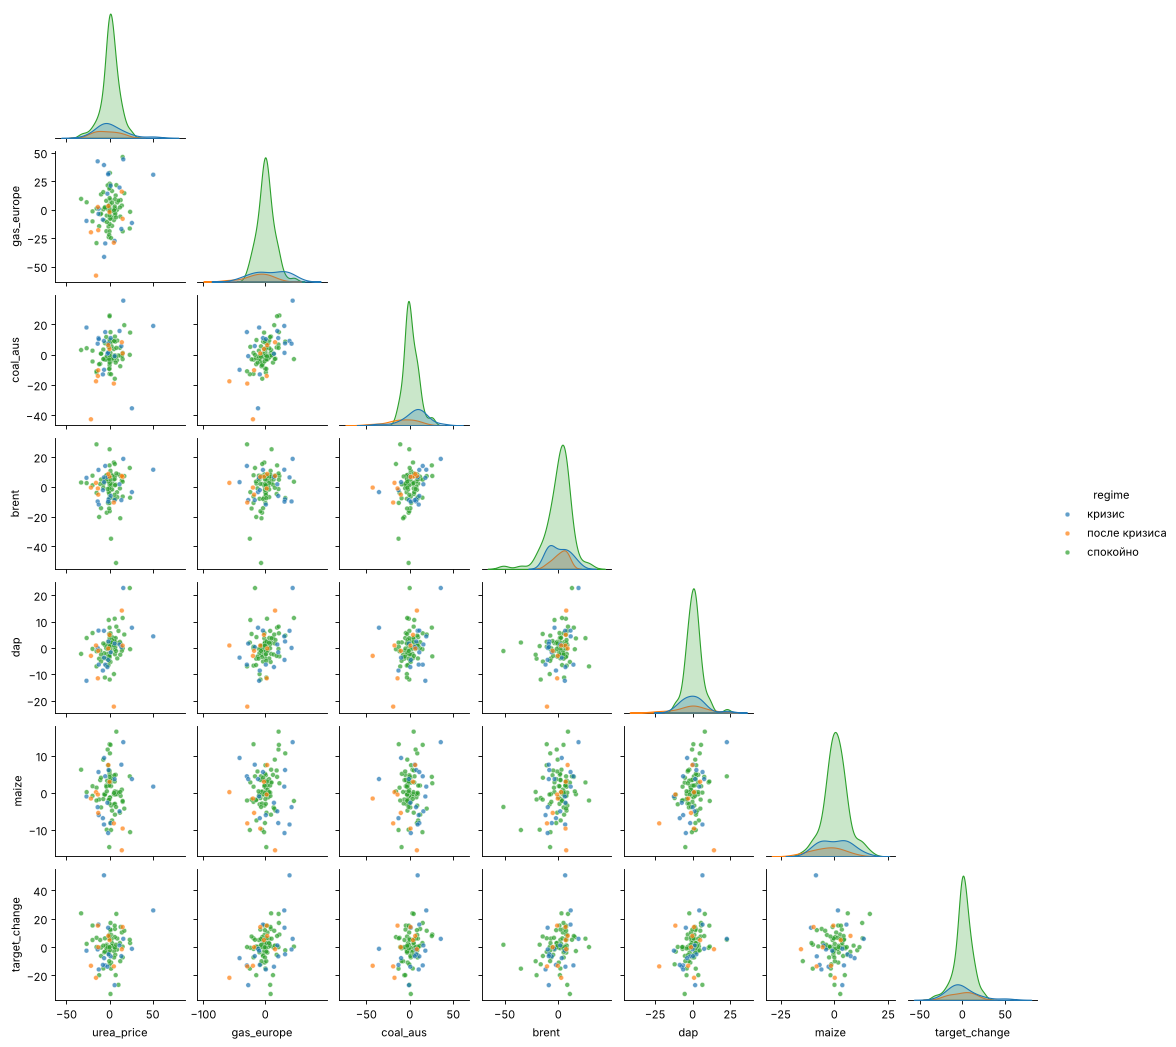

In [10]:
pair = np.log(train[["urea_price", "gas_europe", "coal_aus", "brent", "dap", "maize"]]).diff() * 100
pair["target_change"] = train["target_change"] * 100
pair["regime"] = train["regime"]
sns.pairplot(pair.dropna(), hue="regime", corner=True, plot_kws={"s": 18, "alpha": 0.7}, height=1.9)
plt.show()

**Вывод:** связи между месячными изменениями слабые и шумные — облака почти круглые, лучше всего наклон виден у цели против изменения газа Европы и DAP. Кризисные месяцы дают самые крайние точки и самый большой разброс. Простая линейная связь объясняет небольшую часть колебаний, поэтому для модели нужны признаки шоков, а качество оцениваем отдельно по режимам.

### 2.6. Урезанная корреляционная матрица: отбор признаков
Из 20 рядов оставляем только те, что связаны с целью, и убираем дубли. Всё считаем **на трейне**, чтобы отбор не подсмотрел тест.

1. **Связь с целью:** оставляем признаки, у которых |корреляция изменения сейчас с изменением цены карбамида в следующем месяце| ≥ 0,2 — это порог случайности для 102 месяцев (1,96 / √n).
2. **Убираем дубли:** если два оставшихся признака связаны между собой сильнее 0,75, они несут почти одну информацию — оставляем тот, что сильнее связан с целью.

Шаг 1. Связь с целью |r| ≥ 0.2: оставлено 9 из 19
gas_europe    0.38
dap           0.31
coal_aus      0.28
aluminum      0.28
brent         0.26
coal_safr     0.25
gas_us        0.25
copper        0.22
tsp           0.21
Убраны как не связанные с целью: iron_ore, lng_japan, maize, palm_oil, phosphate_rock, potash, rice, soybeans, sugar, wheat

Шаг 2. Убраны дубли (|r| > 0.75 между признаками): coal_safr (дублирует coal_aus, r = 0.80); tsp (дублирует dap, r = 0.78)
Итог — кандидаты в признаки: gas_europe, dap, coal_aus, aluminum, brent, gas_us, copper


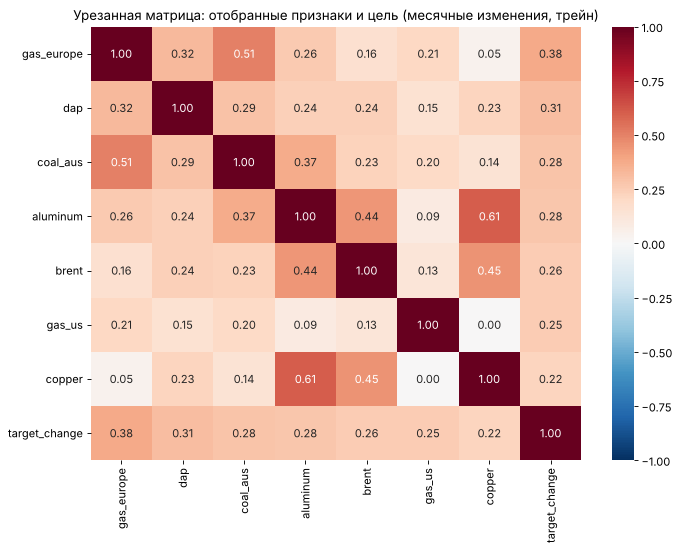

In [11]:
THRESHOLD = round(1.96 / np.sqrt(len(train) - 2), 2)
REDUNDANT = 0.75

changes_train = np.log(train[prices]).diff().drop(columns="urea_price")
link = changes_train.corrwith(train["target_change"])
step1 = link[link.abs() >= THRESHOLD].sort_values(key=abs, ascending=False)
print(f"Шаг 1. Связь с целью |r| ≥ {THRESHOLD}: оставлено {len(step1)} из {len(link)}")
print(step1.round(2).to_string())
print("Убраны как не связанные с целью:", ", ".join(link.index.difference(step1.index)))

corr_sel = changes_train[step1.index].corr()
selected, dropped = [], []
for feature in step1.index:
    twin = [s for s in selected if abs(corr_sel.loc[feature, s]) > REDUNDANT]
    if twin:
        dropped.append(f"{feature} (дублирует {twin[0]}, r = {corr_sel.loc[feature, twin[0]]:.2f})")
    else:
        selected.append(feature)
print(f"\nШаг 2. Убраны дубли (|r| > {REDUNDANT} между признаками):", "; ".join(dropped) if dropped else "нет")
print("Итог — кандидаты в признаки:", ", ".join(selected))

final = changes_train[selected].copy()
final["target_change"] = train["target_change"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(final.corr(), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Урезанная матрица: отобранные признаки и цель (месячные изменения, трейн)")
plt.tight_layout()
plt.show()

**Вывод:** из 19 рядов (без самого карбамида) с изменением цены в следующем месяце значимо связаны 9; после удаления дублей остаются **7 кандидатов**:
- **энергоносители:** газ Европы (самая сильная связь, ≈ 0,38), уголь Австралии, нефть Brent, газ США — экономически понятно: сырьё и топливо для производства;
- **удобрения:** DAP — фосфорно-азотное удобрение, его производят из аммиака, поэтому цены DAP и карбамида двигаются вместе; TSP убран как дубль DAP (r ≈ 0,8), уголь ЮАР — как дубль угля Австралии;
- **металлы:** алюминий и медь — индикаторы мировой промышленной активности. Связь с карбамидом у них слабее объяснима экономически, поэтому оставляем их как кандидатов «под вопросом» и проверим на бейзлайнах.

Убраны как не связанные с целью: зерновые, сахар, пальмовое масло, рис, железная руда, фосфатная руда, калий, СПГ Японии. **Оговорка:** при 19 проверках 1–2 признака могут пройти порог случайно, поэтому окончательный отбор — по качеству прогноза на валидации, а не только по корреляциям.

## 3. Выводы и как используем их дальше

1. **Данные чистые, но неоднородные.** Пропусков в рабочем периоде нет, ошибок ввода нет. Главные проблемы — смены методики (газ 2015, карбамид 2022, калий 2020) и кризисный режим 2021–2022. Решения: период с апреля 2015, флаги смены котировки и режима.
2. **Цена карбамида блуждает, надбавка — стационарна при k ≈ 12.** Наклон цены по газу по данным ≈ 12 (цена перекладывает около половины подорожания газа), а не технические 26. На трейне надбавка при k = 12 уверенно стационарна (ADF t = −3,50), при k = 26 — на границе (t = −2,86). Окончательный k выбираем по ошибке прогноза на валидации.
3. **Выбросы — это шоки, а не ошибки.** Не удаляем; оцениваем качество отдельно для спокойных и кризисных месяцев.
4. **Корреляции уровней обманчивы, работаем с изменениями.** После урезания матрицы остаются 7 кандидатов: изменения газа Европы, угля Австралии, нефти, газа США, DAP, алюминия и меди за последний месяц; плюс надбавка и флаги режима и смены котировки.
5. **Бейзлайн сильный.** Наивный прогноз «цена как в прошлом месяце» ошибается в среднем на 7% в спокойные месяцы и на 12% в кризис. Простые модели на одних ценах выигрывают у него вне кризиса, но проигрывают в кризис (см. 03_k_naive_backtest.ipynb). Выигрыш на шоках должны дать признаки, которых нет в ценах: трафик через проливы (PortWatch), ограничения экспорта Китая, давление на цепочки поставок (GSCPI).
6. **Практическая применимость.** Пользователю (закупщику удобрений) нужен прогноз цены на 1–3 месяца и понимание, из чего он складывается. Разложение «газ + надбавка» даёт и прогноз, и объяснение, и сценарий «газ +30%». Данные Pink Sheet выходят в начале следующего месяца, поэтому прогноз обновляется раз в месяц после выхода данных.

**Дальше:** собрать единую таблицу признаков (Pink Sheet + PortWatch + GSCPI + ставки) в SQL, построить бейзлайны (наивный, SARIMA, линейная модель, бустинг) на общем бэктесте и сравнить MSPE с наивным прогнозом по режимам.